In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Model
from sklearn.neighbors import KNeighborsClassifier
# Train Test
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
# Preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler
# Metrics
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [2]:
df = pd.read_csv('Dataset/student.csv')
df.head(2)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,higher education,higher education,at_home,teacher,...,very good,medium,high,very low,very low,good,6,5,6,6
1,GP,F,17,U,GT3,T,primary education (4th grade),primary education (4th grade),at_home,other,...,excellent,medium,medium,very low,very low,good,4,5,5,6


In [3]:
df['G3'].sort_values(ascending=False).unique()

array([20, 19, 18, 17, 16, 15, 14, 13, 12, 11, 10,  9,  8,  7,  6,  5,  4,
        0])

In [4]:
def convertGrade(grade):
    if grade >= 15:
        return 'A'
    elif grade >= 11:
        return 'B'
    elif grade >= 7:
        return 'C'
    else:
        return 'D'

In [5]:
df['Grade'] = df['G3'].apply(convertGrade)

In [6]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3', 'Grade'],
      dtype='str')

In [7]:
str_columns = ['Medu', 'Fedu', 'traveltime', 'studytime', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'Grade']
int_columns = ['failures', 'absences', 'G1', 'G2']
lbl_encode_columns = ['schoolsup', 'famsup', 'internet']

## Label Encoding

In [8]:
le = LabelEncoder()
for col in lbl_encode_columns:
    df[f'{col}_id'] = le.fit_transform(df[col])

In [9]:
df['health'].unique()

<ArrowStringArray>
['good', 'excellent', 'very bad', 'bad', 'very good']
Length: 5, dtype: str

In [10]:
data = {
    'none': 0,
    'primary education (4th grade)': 1,
    '5th to 9th grade': 2,
    'secondary education': 3,
    'higher education': 4
}
df['Medu_id'] = df['Medu'].map(data)

In [11]:
def manualEncode(dataframe, col_name, *args):
    encode_data = {}
    for idx, val in enumerate(args):
        encode_data[val] = idx

    dataframe[f'{col_name}_id'] = dataframe[col_name].map(encode_data)
    print(f'{col_name} data encoded.')

In [12]:
manualEncode(df, 'Fedu', 'none', 'primary education (4th grade)', '5th to 9th grade', 'secondary education', 'higher education')

Fedu data encoded.


In [13]:
manualEncode(df, 'traveltime', '<15 min.', '15 to 30 min.', '30 min. to 1 hour', '>1 hour')

traveltime data encoded.


In [14]:
manualEncode(df, 'studytime', '<2 hours', '2 to 5 hours', '5 to 10 hours', '>10 hours')

studytime data encoded.


In [15]:
columns = ['freetime', 'goout', 'Dalc', 'Walc']
for col in columns:
    manualEncode(df, col, 'very low',  'low', 'medium', 'high', 'very high')

freetime data encoded.
goout data encoded.
Dalc data encoded.
Walc data encoded.


In [16]:
manualEncode(df, 'health', 'very bad', 'bad', 'good', 'very good', 'excellent')

health data encoded.


In [17]:
manualEncode(df, 'Grade', 'D', 'C', 'B', 'A')

Grade data encoded.


## Features and Target

In [18]:
features = ['Medu_id', 'Fedu_id', 'traveltime_id', 'studytime_id', 'failures', 'schoolsup_id', 
            'famsup_id', 'internet_id', 'freetime_id', 'goout_id', 'health_id', 'absences', 'G1', 'G2']
target = 'Grade_id'

In [19]:
X = df[features]
Y = df[target]

## Train Test Split

In [20]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

## Feature Scaling

In [21]:
scaler = StandardScaler()
X_train_scale = scaler.fit_transform(X_train)
X_test_scale = scaler.transform(X_test)

## Elbow Method - To find optimal number of neighbors

In [22]:
k_range = range(1, 21)
error_rate = []
accuracy_rate = []

for i in k_range:
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(X_train_scale, Y_train)
    knn_pred = knn.predict(X_test_scale)
    error_rate.append(np.mean(Y_test != knn_pred)) # total wrong data / total number of test data
    accuracy_rate.append(accuracy_score(Y_test, knn_pred))

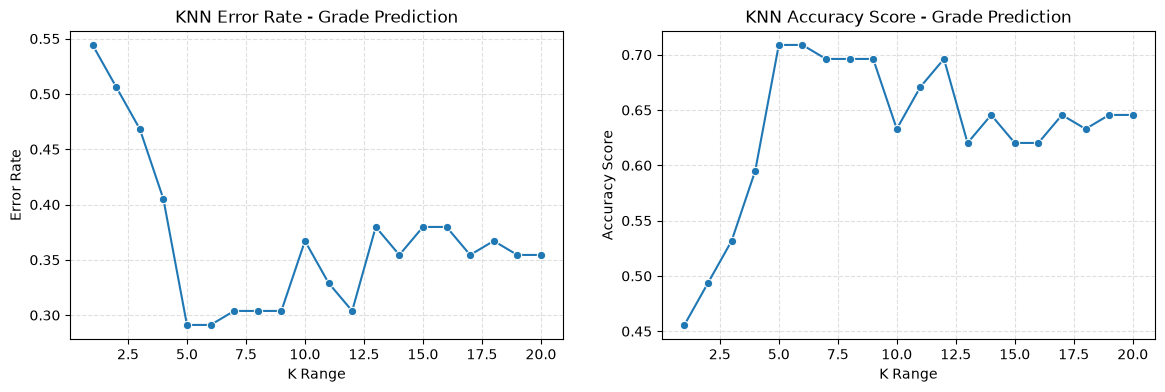

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

ax1 = axes[0]
sns.lineplot(x=k_range, y=error_rate, ax=ax1, marker='o')
ax1.set_xlabel('K Range')
ax1.set_ylabel('Error Rate')
ax1.set_title('KNN Error Rate - Grade Prediction')
ax1.grid(linestyle='--', alpha=0.4)

ax2 = axes[1]
sns.lineplot(x=k_range, y=accuracy_rate, ax=ax2, marker='o')
ax2.set_xlabel('K Range')
ax2.set_ylabel('Accuracy Score')
ax2.set_title('KNN Accuracy Score - Grade Prediction')
ax2.grid(linestyle='--', alpha=0.4)

plt.show()

## Model Implementation

In [24]:
k = 5
model = KNeighborsClassifier(n_neighbors=k, n_jobs=1)
model.fit(X_train_scale, Y_train)
Y_pred = model.predict(X_test_scale)

## Metrics

In [25]:
cr = classification_report(Y_test, Y_pred)
cm = confusion_matrix(Y_test, Y_pred)

In [26]:
print(cr)

              precision    recall  f1-score   support

           0       0.67      0.50      0.57        12
           1       0.62      0.72      0.67        25
           2       0.74      0.74      0.74        27
           3       0.86      0.80      0.83        15

    accuracy                           0.71        79
   macro avg       0.72      0.69      0.70        79
weighted avg       0.71      0.71      0.71        79



In [27]:
print(cm)

[[ 6  6  0  0]
 [ 3 18  4  0]
 [ 0  5 20  2]
 [ 0  0  3 12]]


## Cross Validation

In [28]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_error_rate = []
cv_accuracy_rate = []

for i in k_range:
    knn_fold = KNeighborsClassifier(n_neighbors=i, n_jobs=1)
    cv_score = cross_val_score(knn_fold, X_train_scale, Y_train, scoring='accuracy')

    cv_error_rate.append(cv_score.mean())
    cv_accuracy_rate.append(1 - cv_score.mean())

best_elbow = k_range[np.argmax(cv_accuracy_rate)]
print(f'Optimal Neighbor after Cross Validation: {best_elbow}')

Optimal Neighbor after Cross Validation: 2


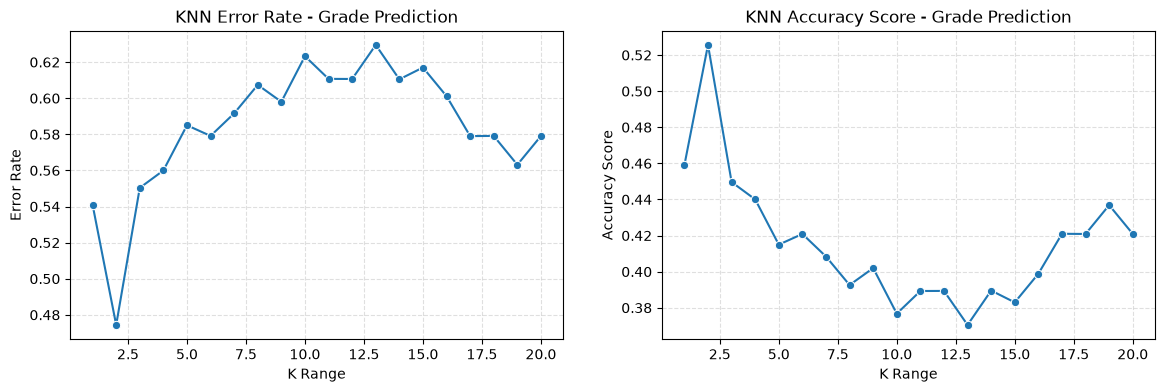

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

ax1 = axes[0]
sns.lineplot(x=k_range, y=cv_error_rate, ax=ax1, marker='o')
ax1.set_xlabel('K Range')
ax1.set_ylabel('Error Rate')
ax1.set_title('KNN Error Rate - Grade Prediction')
ax1.grid(linestyle='--', alpha=0.4)

ax2 = axes[1]
sns.lineplot(x=k_range, y=cv_accuracy_rate, ax=ax2, marker='o')
ax2.set_xlabel('K Range')
ax2.set_ylabel('Accuracy Score')
ax2.set_title('KNN Accuracy Score - Grade Prediction')
ax2.grid(linestyle='--', alpha=0.4)

plt.show()

## Grid Search Cross Validation

In [30]:
'''
Grid Search Parameters
------------------------
n_neighbors = k_range
weights = 'uniform' / 'distance'
metric = 'euclidean' / 'manhattan'
'''

"\nGrid Search Parameters\n------------------------\nn_neighbors = k_range\nweights = 'uniform' / 'distance'\nmetric = 'euclidean' / 'manhattan'\n"

In [31]:
params = {
    'n_neighbors':list(range(1, 36)),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']    
}

In [32]:
grid_cv = GridSearchCV(
    estimator = KNeighborsClassifier(),
    param_grid = params,
    cv = kfold,
    n_jobs=1
)
grid_cv.fit(X_train_scale, Y_train)
best_est = grid_cv.best_estimator_

In [33]:
print(best_est)

KNeighborsClassifier(metric='manhattan', n_neighbors=20, weights='distance')


In [34]:
best_k_pred = grid_cv.predict(X_test_scale)

In [35]:
g_cr = classification_report(Y_test, best_k_pred)
print(g_cr)

              precision    recall  f1-score   support

           0       1.00      0.42      0.59        12
           1       0.68      0.84      0.75        25
           2       0.71      0.81      0.76        27
           3       0.92      0.73      0.81        15

    accuracy                           0.75        79
   macro avg       0.83      0.70      0.73        79
weighted avg       0.78      0.75      0.74        79



## SVM

In [22]:
from sklearn.svm import SVC

In [51]:
svc_model = SVC(
    kernel='linear',
    C = 1,
    class_weight='balanced'
)
svc_model.fit(X_train_scale, Y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [52]:
svc_pred = svc_model.predict(X_test_scale)

In [53]:
svc_cr = classification_report(Y_test, svc_pred)
print(svc_cr)

              precision    recall  f1-score   support

           0       0.67      1.00      0.80        12
           1       0.83      0.76      0.79        25
           2       0.95      0.74      0.83        27
           3       0.82      0.93      0.88        15

    accuracy                           0.82        79
   macro avg       0.82      0.86      0.83        79
weighted avg       0.84      0.82      0.82        79

